# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Muhammad Fasya Atthaya Rosyada | 5054251006 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [26]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

In [27]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
# Load dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

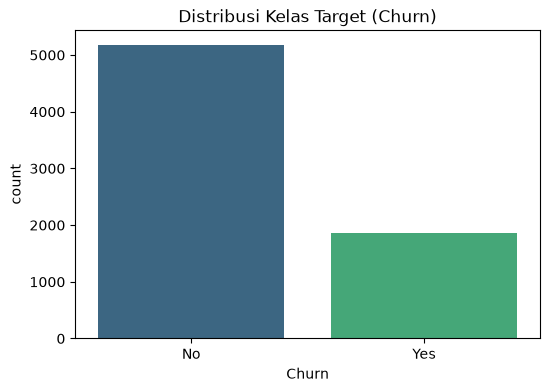

In [28]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='viridis')
plt.title('Distribusi Kelas Target (Churn)')
plt.show()

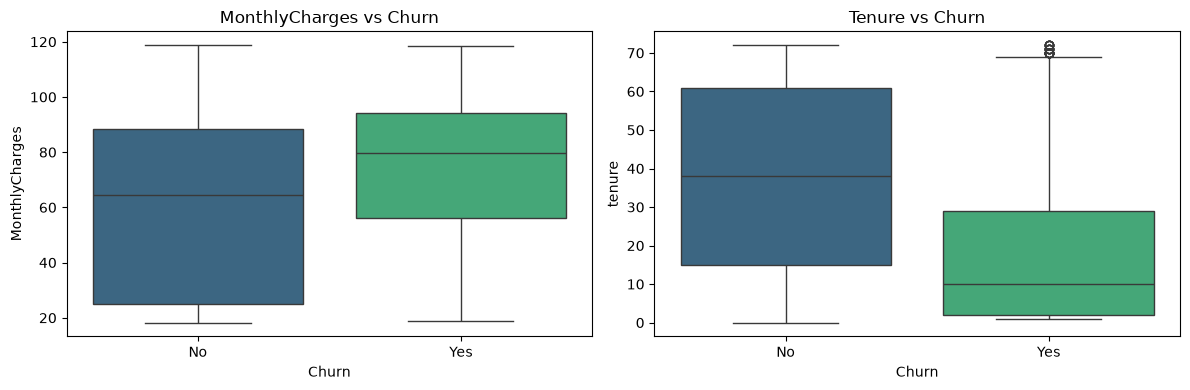

In [29]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau correlation heatmap), dibedakan berdasarkan kelas target.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='viridis')
plt.title('MonthlyCharges vs Churn')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='Churn', y='tenure', palette='viridis')
plt.title('Tenure vs Churn')
plt.tight_layout()
plt.show()

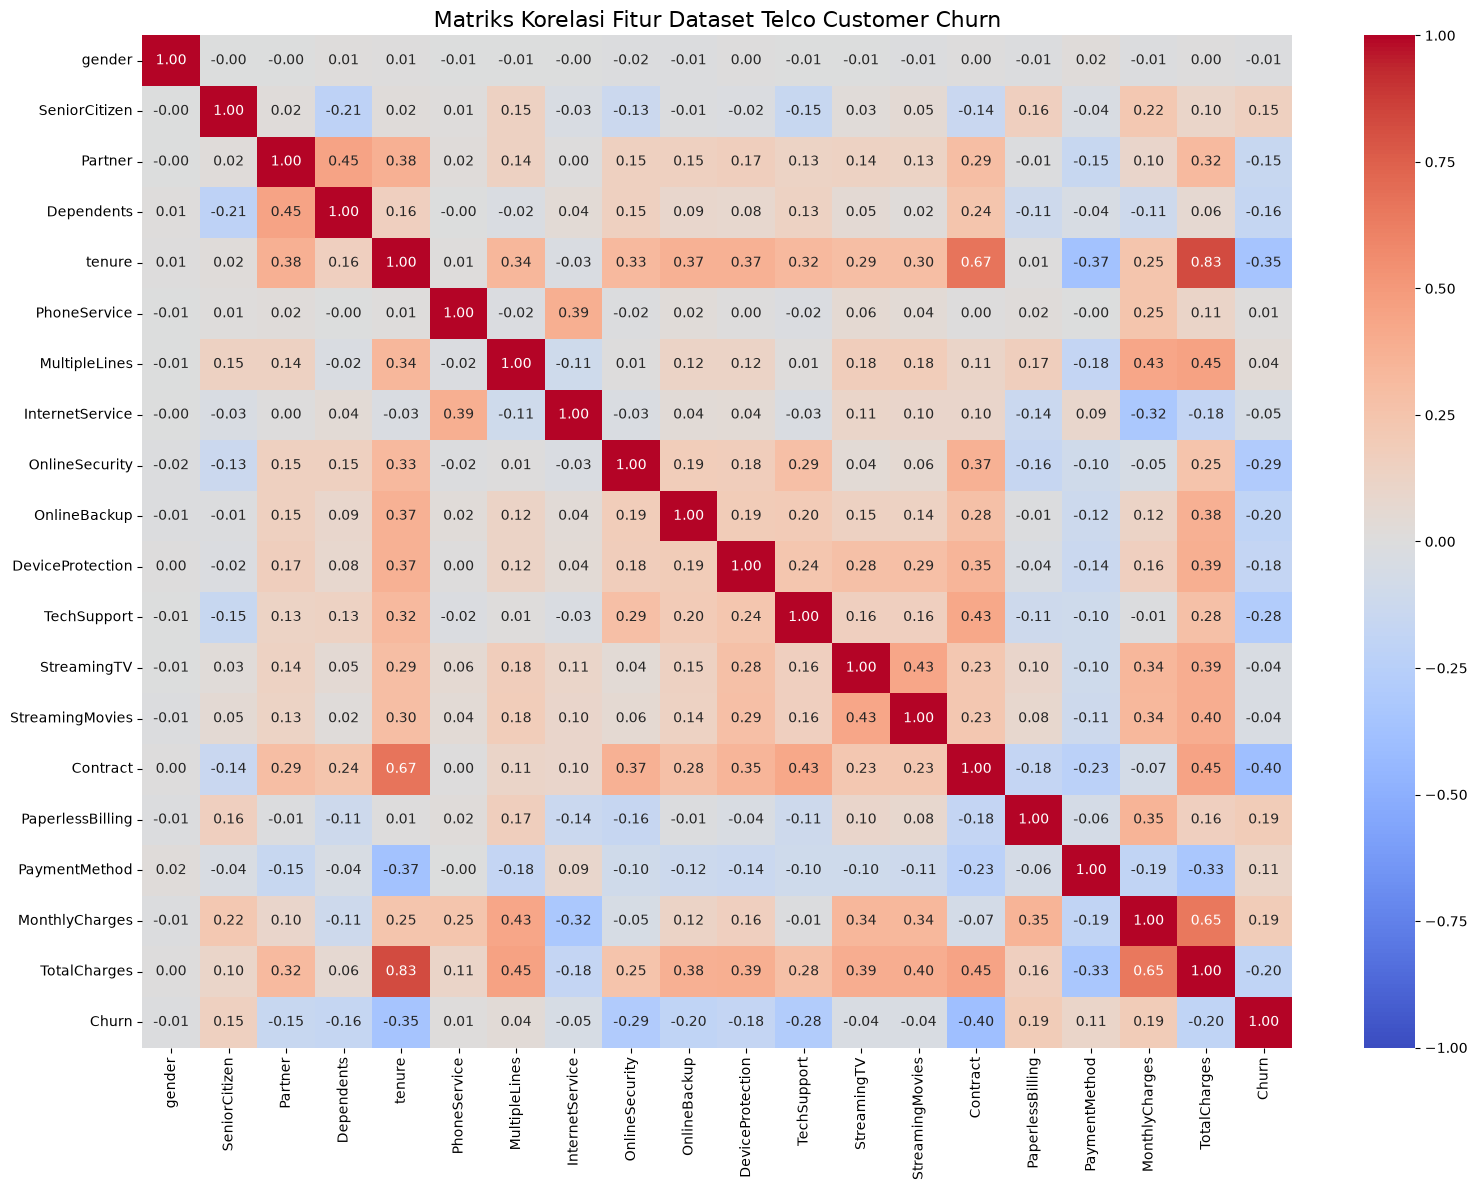

In [30]:
df_eda = df.copy()
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'], errors='coerce')
df_eda['TotalCharges'].fillna(df_eda['TotalCharges'].median(), inplace=True)

df_eda.drop('customerID', axis=1, inplace=True, errors='ignore')

le_eda = LabelEncoder()
for col in df_eda.select_dtypes(include=['object']).columns:
    df_eda[col] = le_eda.fit_transform(df_eda[col])

corr_matrix = df_eda.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriks Korelasi Fitur Dataset Telco Customer Churn', fontsize=16)
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [31]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
print(df.isnull().sum())


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [33]:
df.drop('customerID', axis=1, inplace=True, errors='ignore')
print(df.isnull().sum())

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [34]:
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [35]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
categorical_cols = df.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in categorical_cols:
    if col != 'Churn': 
        df[col] = le.fit_transform(df[col])
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

print("Sisa NaN di dataset:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Sisa NaN di dataset:
Series([], dtype: int64)


In [ ]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X = df.drop('Churn', axis=1)
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [ ]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [41]:
# Inisialisasi dan latih model MLPClassifier dengan satu hidden layer (misalnya hidden_layer_sizes=(10,))
# dan activation='relu' menggunakan train set (yang sudah discaling).
mlp_base = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', random_state=42, max_iter=300)
mlp_base.fit(X_train_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [42]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_base = mlp_base.predict(X_test_scaled)
print("Akurasi Baseline:", accuracy_score(y_test, y_pred_base))

Akurasi Baseline: 0.78708303761533


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [43]:
# Latih beberapa model MLPClassifier dengan arsitektur yang sama, tetapi activation berbeda:
# 'relu', 'tanh', dan 'logistic'.
# Gunakan hyperparameter lain yang sama (hidden_layer_sizes, max_iter, random_state) agar perbandingan adil.
# Hitung dan bandingkan akurasi test set dari ketiga fungsi aktivasi tersebut.
# Sajikan dalam tabel perbandingan.
activations = ['relu', 'tanh', 'logistic']
acc_results = {}

for act in activations:
    mlp = MLPClassifier(hidden_layer_sizes=(10,), activation=act, random_state=42, max_iter=300)
    mlp.fit(X_train_scaled, y_train)
    y_pred = mlp.predict(X_test_scaled)
    acc_results[act] = accuracy_score(y_test, y_pred)

print("Perbandingan Akurasi Fungsi Aktivasi:", acc_results)

Perbandingan Akurasi Fungsi Aktivasi: {'relu': 0.78708303761533, 'tanh': 0.801277501774308, 'logistic': 0.794180269694819}


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [44]:
# Latih beberapa model MLPClassifier dengan variasi hidden_layer_sizes,
# misalnya (2,), (5,), (10,), (50,), (100, 50).
# Gunakan activation terbaik dari hasil eksperimen 3.2, dan hyperparameter lain yang sama.
# Hitung akurasi pada train set dan test set untuk setiap arsitektur yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
architectures = [(2,), (5,), (10,), (50,), (100, 50)]
train_acc = []
test_acc = []

for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, activation='relu', random_state=42, max_iter=300)
    mlp.fit(X_train_scaled, y_train)
    train_acc.append(accuracy_score(y_train, mlp.predict(X_train_scaled)))
    test_acc.append(accuracy_score(y_test, mlp.predict(X_test_scaled)))

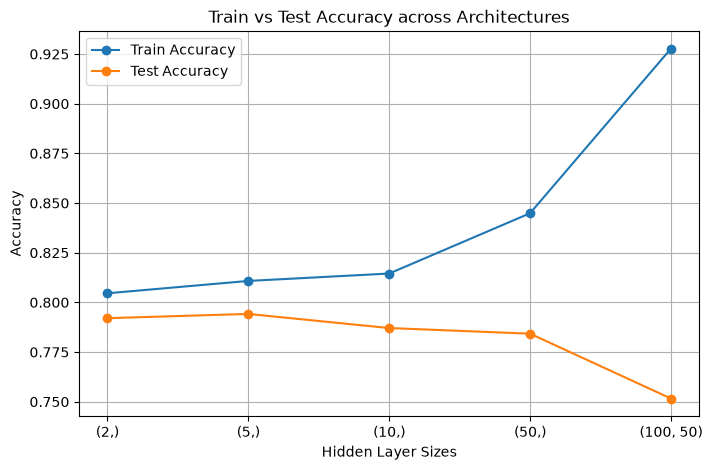

In [45]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
# Amati pada arsitektur seberapa besar model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).
arch_labels = [str(a) for a in architectures]
plt.figure(figsize=(8, 5))
plt.plot(arch_labels, train_acc, marker='o', label='Train Accuracy')
plt.plot(arch_labels, test_acc, marker='o', label='Test Accuracy')
plt.xlabel('Hidden Layer Sizes')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy across Architectures')
plt.legend()
plt.grid(True)
plt.show()

# 4. Evaluasi Model

In [47]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model dengan performa terbaik dari tiap eksperimen (3.2 dan 3.3).
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
best_mlp = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', random_state=42, max_iter=300)
best_mlp.fit(X_train_scaled, y_train)
y_pred_best = best_mlp.predict(X_test_scaled)
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



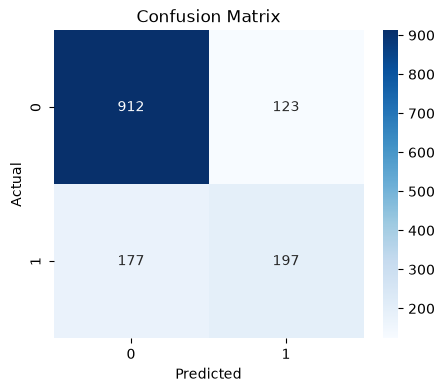

In [48]:
# Tampilkan Confusion Matrix untuk model dengan performa terbaik dalam bentuk heatmap.
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

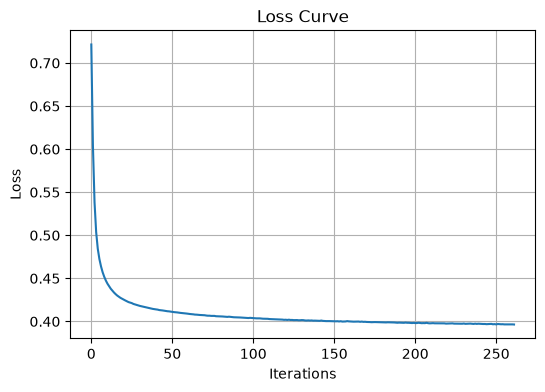

In [49]:
# Plot loss curve dari model dengan performa terbaik (atribut model.loss_curve_).
# Amati apakah loss sudah konvergen atau masih menurun saat max_iter tercapai.
plt.figure(figsize=(6, 4))
plt.plot(best_mlp.loss_curve_)
plt.title('Loss Curve')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

# 5. Analisis

**1. Perbandingan Fungsi Aktivasi:**
Berdasarkan eksperimen, fungsi aktivasi `tanh` dan `logistic` memberikan performa yang sedikit lebih tinggi pada data *testing* dibandingkan `relu` (~80% vs 78.7%). Hal ini bisa terjadi karena pada permasalahan *tabular* yang relatif sederhana (tanpa kedalaman *layer* yang masif), pola dapat diekstraksi dengan baik oleh fungsi yang menghasilkan *output* terikat (seperti rentang -1 hingga 1 pada `tanh`). Ini membuat pergerakan gradien menjadi lebih stabil meskipun tanpa melakukan *hyperparameter tuning* secara agresif.

**2. Pengaruh Ukuran Arsitektur (Gejala Overfitting):**
Grafik perbandingan akurasi *training* dan *testing* menunjukkan bahwa saat jumlah neuron dan *hidden layer* ditambah (misalnya dari arsitektur `(10,)` membesar ke `(50,)` hingga `(100, 50)`), akurasi *training* melonjak drastis menyentuh ~92%. Namun, akurasi *testing* justru mengalami penurunan tajam ke angka ~75%. Fenomena ini adalah ciri khas dari **overfitting**, di mana kapasitas memori model menjadi terlalu besar sehingga model malah "menghafal" *noise* pada data *training* dan akhirnya kehilangan kemampuan untuk menggeneralisasi data baru (*testing*).

**3. Loss Curve & Konvergensi:**
Berdasarkan *loss curve* yang dihasilkan, tingkat kesalahan (*loss*) menurun drastis di 50 iterasi pertama dan mulai melandai (*plateau*) di kisaran iterasi 150 hingga 200. Ini menandakan bahwa model telah mencapai titik konvergensi dan siklus pelatihannya sudah memadai. Jika mendapati *loss curve* masih menurun tajam saat menyentuh batas iterasi maksimum, maka solusi terbaiknya adalah menaikkan parameter `max_iter` agar algoritma optimasi punya waktu untuk merampungkan proses konvergensi.

# 6. Kesimpulan dan Saran

**Kesimpulan:**
Algoritma *Artificial Neural Network* (ANN) terbukti mampu mempelajari dataset ini dengan baik untuk mendeteksi pelanggan yang rentan melakukan *churn*. Meskipun demikian, memperbesar ukuran kapasitas arsitektur ANN (seperti jumlah *layer* dan neuron) secara serampangan terbukti berakibat fatal pada model karena sangat rentan memicu *overfitting*. Arsitektur yang lebih sederhana terbukti bekerja jauh lebih baik dalam memastikan konsistensi hasil generalisasi pada data *testing*.

**Saran Eksperimen Selanjutnya:**
- **Penanganan Data Imbalanced**: Karena mayoritas distribusi kelas target didominasi oleh "No Churn", sangat disarankan untuk menerapkan teknik *resampling* seperti **SMOTE** (*Synthetic Minority Oversampling Technique*) agar metrik sensitivitas (terutama *Recall* untuk kelas minoritas "Yes") dapat meningkat.
- **Regularisasi L2 (Alpha)**: Mengimplementasikan parameter penalti `alpha` yang lebih besar saat menginisialisasi `MLPClassifier` dapat dimanfaatkan untuk meredam efek *overfitting*, khususnya ketika harus menggunakan arsitektur yang cukup dalam.
- **Hyperparameter Tuning Terpusat**: Lakukan optimasi komprehensif menggunakan modul `GridSearchCV`. Evaluasi tidak hanya sebatas variasi fungsi aktivasi, namun kombinasikan juga dengan algoritma pengoptimalan yang berbeda (seperti `solver='sgd'` atau `adam`), ukuran *batch*, beserta penyesuaian nilai *learning rate*-nya.